In [1]:
# Initialization, styling configuration, and helper utilities
%matplotlib inline

import json
import os

import joblib
import numpy as np
import pandas as pd
import sklearn
from IPython.display import Markdown, display
from scipy.stats import ks_2samp
from sklearn.datasets import make_classification
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix, f1_score,
                             precision_score,
                             recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# Course helpers: installed from PyPI in Colab, from the repository's .venv locally
import sys
if "google.colab" in sys.modules:
    %pip install -q dl-course
from dl_course import foundations as hp

hp.setup_theme()

# Machine Learning Operations (MLOps)
### The Engineering Lifecycle of ML-Powered Software

Interactive lecture slides based on [ml-ops.org](https://ml-ops.org) (CRISP-ML(Q)) and standard principles of statistical decision theory and quality assurance.

- **Why MLOps?** The Three Levels of ML Software (Data, Model, Code)
- **The CRISP-ML(Q) Process Model** (6 Lifecycle Phases, Quality Assurance in Every Phase)
- **Phase 1: Business & Data Understanding** (KPIs & Non-ML Baselines)
- **Phase 2: Data Engineering** (Validation, Imputation, Data Splits & DVC Versioning)
- **Phase 3: Model Engineering** (Inductive Bias & Model Packaging)
- **Phase 4: Quality Assurance & Decision Theory** (Confusion Matrix, Precision & Recall, Expected Loss, ROC/AUC)
- **Phase 5: Deployment Patterns** (REST APIs, Batch Scoring & Edge Models)
- **Phase 6: Monitoring & Maintenance** (Covariate Shift, Concept Drift & Continuous Training CT)
- **Hands-On End-to-End Tutorial Lab**

# Why MLOps?

- In traditional software engineering, developers write algorithmic logic that transforms input data into outputs:
  $$\text{Input} + \text{Code} \implies \text{Output}$$
- In machine learning, algorithms discover patterns from data and outputs to generate the program:
  $$\text{Input} + \text{Output} \implies \text{Model}$$
- **The Challenge:** ML applications are not just code — they are a tightly coupled trinity of **Data**, **Model**, and **Code**.

> 📘 **Definition: Machine Learning Operations (MLOps)**
>
> An engineering discipline that unifies ML system development (Dev) with operations (Ops) to standardize, automate, and monitor the continuous delivery of reproducible, testable, and evolvable ML products in production.

<small>📖 *Source: [ml-ops.org](https://ml-ops.org); Continuous Delivery Foundation SIG MLOps*</small>


## The Three Levels of ML-Powered Software

- **Data Engineering Pipeline**: Ingestion, validation, cleaning, feature transformation, and data versioning.
- **ML Model Pipeline**: Algorithm selection, distributed training, hyperparameter optimization, and acceptance testing.
- **Application / Software Pipeline**: Packaging (ONNX, Docker), serving endpoints (REST/gRPC), monitoring, and automated retraining triggers.

# The CRISP-ML(Q) Process Model

To overcome the ad-hoc nature of early ML projects, **CRISP-ML(Q)** (*Cross-Industry Standard Process for the development of Machine Learning applications with Quality assurance methodology*) organizes a project into six phases:

<center>
    <img src="https://raw.githubusercontent.com/konstantin-schekotihin/dl_course/master/shared/images/mlops_crisp_cycle.svg" width="75%"/>
</center>

1. **Business & Data Understanding**: Objectives, success KPIs, non-ML baseline.
2. **Data Engineering**: Exploration, wrangling, labeling, splitting, and versioning.
3. **Machine Learning Model Engineering**: Model selection, inductive bias, training, hyperparameter tuning.
4. **Quality Assurance (Model Evaluation)**: Decision theory, performance metrics on held-out validation and test data, robustness, fairness.
5. **Deployment**: Serving architectures (batch, real-time, edge), canary and shadow rollouts.
6. **Monitoring & Maintenance**: Covariate shift, concept drift, and the Continuous Training (CT) feedback loop.

The **(Q)** is not a single phase: in every phase, the methodology names the requirements, the risks and the quality checks that mitigate them.

<small>📖 *Source: [Studer, S., et al. (2021). Towards CRISP-ML(Q): A machine learning process model with quality assurance methodology. Machine Learning and Knowledge Extraction, 3(2), 392–413](https://doi.org/10.3390/make3020020)*</small>

# Business & Data Understanding

- **Establish Clear, Measurable KPIs**:
  - Technical metrics (e.g. Accuracy, AUC) must directly translate into business/scientific KPIs (e.g. reduction in missed cancer lesions, reduction in customer churn, monetary savings).
- **The Non-ML Baseline (Crucial Best Practice)**:
  - Before training complex neural networks, always implement a simple rule-based heuristic or a **majority-class baseline** (always predict the most frequent class).
  - *Why?* A non-ML baseline establishes the minimum performance threshold. If an expensive deep model cannot significantly beat a simple heuristic, the ML project is economically unjustified.
- **Feasibility Assessment & The Machine Learning Canvas**:
  - Are sufficient high-quality training observations available?
  - What are the latency, throughput, privacy, and regulatory constraints?

# Data Engineering

- **Data Ingestion & Quality Profiling**:
  - Scan for schema anomalies, missing values, multimodal distributions, and label inconsistencies.
- **Data Wrangling & Imputation**:
  - Impute missing features (median/mean for numerical, mode for categorical) with pipeline transformers fitted on the training split only.
- **Data Versioning (DVC — Data Version Control)**:
  - Code is versioned with Git; large datasets are impractical to store in a Git repository (Git LFS exists, but only stores large files).
  - Tools like **DVC** compute content hashes (e.g. md5) of dataset files, storing lightweight `.dvc` tracking pointers in Git while syncing large binary artifacts to remote object storage (S3, GCS, MinIO).
- **Dataset Partitioning**:
  - **Training Set** (~70%): Used to optimize model parameters $\mathbf{w}$.
  - **Validation Set** (~15%): Used to tune hyperparameters, choose model architectures and set decision thresholds.
  - **Test Set** (~15%): Held out until final acceptance testing to measure generalization, used once.
- **Standardization with training statistics** *(from Lecture 04_algebra)*: $\tilde{x}_{ni} = (x_{ni} - \mu_i) / \sigma_i$ for feature $i$ of example $n$, where $\mu_i$ and $\sigma_i$ are the mean and standard deviation of feature $i$ in the **training** split; validation and test data reuse the same $\mu_i$, $\sigma_i$.

> ⚠️ **Important:** Never use future data to predict past events (use temporal splits for time-series), and fit scalers, imputers and all other preprocessing on the training split only; otherwise information from the test set leaks into the model.

# Model Engineering & Inductive Bias

> 💡 **Key Takeaway: Learning Needs Assumptions (Inductive Bias)**
>
> *"A learner that makes no a priori assumptions regarding the identity of the target concept has no rational basis for classifying any unseen instances."*

<small>📖 — *Tom M. Mitchell (1997), Machine Learning, McGraw-Hill*</small>

- Every learning algorithm incorporates an **inductive bias**; no algorithm is best for every problem (the *no free lunch theorem*):
  - Linear models assume that a hyperplane separates the classes (or fits the targets).
  - Convolutional networks assume spatial translation equivariance and local connectivity.
  - Recurrent networks assume sequential temporal structure.
- **Model Selection Workflow**:
  - Begin with simple interpretable baselines (Logistic Regression, Decision Trees).
  - Scale up to expressive architectures (Deep Neural Nets, Ensembles) only if they improve the validation metric by more than its run-to-run variation (e.g. across random seeds or data splits).
- **Model Packaging**:
  - Exporting trained model artifacts into interoperable formats: **ONNX** (Open Neural Network Exchange, via `torch.onnx.export`) or `torch.export` for PyTorch models; `joblib` or `skops` files for scikit-learn pipelines; Docker images that bundle model, code and dependencies.

# Quality Assurance & Decision Theory

How do we evaluate whether a model is safe and effective for production deployment?

- **Binary classification:** class $\mathcal{C}_1$ (positive, e.g. a loan that defaults) is coded as target $t = 1$, class $\mathcal{C}_2$ (negative) as $t = 0$.
- A probabilistic classifier such as **logistic regression** outputs $y(\mathbf{x}) = \sigma(\mathbf{w}^\mathrm{T}\mathbf{x} + w_0)$ with weights $\mathbf{w}$ and bias $w_0$, an estimate of the posterior probability $p(\mathcal{C}_1 \mid \mathbf{x})$; how it is trained follows *(→ Lecture 05_classification)*.
- A **decision** turns this probability into a predicted class $\hat{t} \in \{0, 1\}$, e.g. $\hat{t} = 1$ if $y(\mathbf{x}) \ge \tau$ for a threshold $\tau$.
- Quality assurance asks two separate questions: how good are the probabilities (**inference**), and how good are the decisions made from them (**decision**)?

## The Confusion Matrix

- Comparing the predictions $\hat{t}$ with the true targets $t$ on $N$ held-out examples partitions them into four outcomes (rows: true class, columns: predicted class, negatives first):

| | Predicted negative ($\hat{t} = 0$) | Predicted positive ($\hat{t} = 1$) |
| :-- | :-- | :-- |
| **True negative class** ($t = 0$, $\mathcal{C}_2$) | True Negative ($\mathrm{TN}$) | False Positive ($\mathrm{FP}$), type I error |
| **True positive class** ($t = 1$, $\mathcal{C}_1$) | False Negative ($\mathrm{FN}$), type II error | True Positive ($\mathrm{TP}$) |

- **Type I Error ($\mathrm{FP}$)**: A negative instance incorrectly flagged as positive (false alarm).
- **Type II Error ($\mathrm{FN}$)**: A positive instance incorrectly missed (missed detection).
- $N = \mathrm{TN} + \mathrm{FP} + \mathrm{FN} + \mathrm{TP}$. This layout is also the one returned by scikit-learn's `confusion_matrix`: `[[TN, FP], [FN, TP]]`.

## Classification Metrics: Precision, Recall, & $F_1$

| Metric | Formula | Question it answers |
| :-- | :-- | :-- |
| **Accuracy** | $(\mathrm{TP} + \mathrm{TN}) / N$ | Fraction of correct predictions; highly misleading under class imbalance |
| **Precision** | $\mathrm{TP} / (\mathrm{TP} + \mathrm{FP})$ | When the model predicts positive, how often is it right? |
| **Recall** (sensitivity, true positive rate $\mathrm{TPR}$) | $\mathrm{TP} / (\mathrm{TP} + \mathrm{FN})$ | Out of all positive cases, how many did the model find? |
| **Specificity** | $\mathrm{TN} / (\mathrm{TN} + \mathrm{FP})$ | Out of all negative cases, how many were correctly cleared? |
| **False positive rate** $\mathrm{FPR}$ | $\mathrm{FP} / (\mathrm{FP} + \mathrm{TN}) = 1 - \mathrm{specificity}$ | How often is a negative case flagged (false alarm)? |
| **False discovery rate** | $\mathrm{FP} / (\mathrm{FP} + \mathrm{TP}) = 1 - \mathrm{precision}$ | Which fraction of the flagged cases are false alarms? |

- **$F_1$-Score**: Harmonic mean balancing precision and recall:
  $$F_1 = \frac{2 \cdot \mathrm{precision} \cdot \mathrm{recall}}{\mathrm{precision} + \mathrm{recall}} = \frac{2\mathrm{TP}}{2\mathrm{TP} + \mathrm{FP} + \mathrm{FN}}$$

## Expected Loss & Cost-Sensitive Decisions

- In real-world applications, different mistakes carry radically asymmetric consequences:
  - In medical screening, a **False Negative** (missing a malignant tumor) is potentially fatal.
  - A **False Positive** (unnecessary follow-up biopsy) incurs minor financial/stress cost.
- **The Loss Matrix $\mathbf{L}$**: $L_{kj}$ is the loss incurred when the true class is $\mathcal{C}_k$ and we decide for class $\mathcal{C}_j$.
- A decision rule assigns each input $\mathbf{x}$ to a decision region $\mathcal{R}_j$ (decide $\mathcal{C}_j$ for $\mathbf{x} \in \mathcal{R}_j$). Its **expected loss** is
  $$\mathbb{E}[L] = \sum_k \sum_j \int_{\mathcal{R}_j} L_{kj}\, p(\mathbf{x}, \mathcal{C}_k)\, \mathrm{d}\mathbf{x}$$
- $\mathbb{E}[L]$ is minimized by deciding, for each $\mathbf{x}$, for the class $j$ with the smallest **conditional risk**
  $$\sum_k L_{kj}\, p(\mathcal{C}_k \mid \mathbf{x})$$
- Only the posteriors $p(\mathcal{C}_k \mid \mathbf{x})$ are needed: **inference** estimates them, the **decision** applies $\mathbf{L}$. If the costs change, only the decision changes; the model need not be retrained.

## From the Loss Matrix to a Decision Threshold

- Two classes, $\mathcal{C}_1$ (default, $t = 1$) and $\mathcal{C}_2$ (no default, $t = 0$); correct decisions cost nothing. Rows are the true classes $\mathcal{C}_1, \mathcal{C}_2$, columns the decisions $\mathcal{C}_1, \mathcal{C}_2$:
  $$\mathbf{L} = \begin{pmatrix} 0 & L_\mathrm{FN} \\ L_\mathrm{FP} & 0 \end{pmatrix}$$
- Decide $\mathcal{C}_1$ when its conditional risk is smaller, $L_\mathrm{FP}\, p(\mathcal{C}_2 \mid \mathbf{x}) < L_\mathrm{FN}\, p(\mathcal{C}_1 \mid \mathbf{x})$. With $p(\mathcal{C}_2 \mid \mathbf{x}) = 1 - p(\mathcal{C}_1 \mid \mathbf{x})$:
  $$p(\mathcal{C}_1 \mid \mathbf{x}) > \tau^\star = \frac{L_\mathrm{FP}}{L_\mathrm{FP} + L_\mathrm{FN}}$$
- Equal costs give $\tau^\star = 0.5$ (the minimum misclassification rate); if a missed default costs four times a wrongly rejected applicant, $\tau^\star = 1/5 = 0.2$.
- This requires **calibrated** probabilities. Class weighting (`class_weight="balanced"`) instead reweights the training errors by the inverse class frequencies; with $\tau = 0.5$ it acts like an implicit loss ratio $L_\mathrm{FN} / L_\mathrm{FP} = N_0 / N_1$ (negatives over positives), and its outputs are no longer estimates of $p(\mathcal{C}_1 \mid \mathbf{x})$. Stating $\mathbf{L}$ explicitly keeps the cost assumption visible.

## ROC Curve & AUC

- Sweeping the threshold $\tau$ from $1$ down to $0$ traces the **receiver operating characteristic (ROC) curve**: true positive rate ($\mathrm{TPR}$, recall) against false positive rate ($\mathrm{FPR}$).
  - $\tau = 1$: no case is flagged, the point $(0, 0)$; $\tau = 0$: every case is flagged, the point $(1, 1)$.
  - Each threshold is one **operating point** on the curve; the loss matrix selects one of them.
- The diagonal $\mathrm{TPR} = \mathrm{FPR}$ corresponds to random guessing.
- **AUC (area under the ROC curve)** summarizes the curve over all thresholds: $1$ for a perfect classifier, $0.5$ for random guessing, and below $0.5$ for a classifier that performs worse than random (its curve lies below the diagonal).
- AUC does not depend on $\tau$ or on the costs: it complements, but does not replace, the expected loss at the chosen operating point.

# Model Deployment & Serving Patterns

How do we serve predictions reliably to end-users and downstream services?

1. **Model-as-a-Service (REST / gRPC Microservice)**:
   - The model is hosted behind a web server (e.g. FastAPI, Triton Inference Server).
   - Client sends JSON feature payload $\implies$ server returns prediction synchronously.
   - *Best for:* Interactive applications, mobile/web backends (latency < 100ms).
2. **Batch Offline Scoring**:
   - Model runs periodically (hourly/nightly cron) over a database table, storing predictions in a cache.
   - *Best for:* High-volume recommendations, periodic risk scores, fraud reports.
3. **Embedded / Edge Model**:
   - Serialized model runs directly inside client applications or IoT edge hardware (CoreML, TFLite).
   - *Best for:* No network round-trip (lowest latency), offline operation, strict privacy.

## Deployment Rollout Strategies
- **Canary Deployment**: Route 5% of traffic to the new model; monitor error rates before scaling to 100%.
- **Blue-Green Deployment**: Run both versions simultaneously; instantly switch router upon verification.
- **Shadow Mode**: New model runs in parallel on live requests, but its outputs are only logged, not shown to users.

# Monitoring, Drift & Continuous Training (CT)

A model in production decays over time because the world is non-stationary.

### The Three Flavors of Production Drift
1. **Covariate Shift (Data Drift)**: The input distribution $p(\mathbf{x})$ shifts over time, but the conditional distribution $p(t \mid \mathbf{x})$ remains constant.
   - *Example*: An imaging sensor changes resolution, or the age distribution of users shifts.
2. **Concept Drift**: The relationship between inputs and targets, $p(t \mid \mathbf{x})$, changes.
   - *Example*: Consumer buying behaviors shift abruptly during an economic crisis; fraud patterns evolve to bypass model filters.
3. **Prior Probability Shift**: The class frequencies $p(t)$ shift, while the class-conditional distributions $p(\mathbf{x} \mid t)$ stay fixed.
   - *Example*: Seasonal flu prevalence spikes in winter. Calibrated posteriors can be corrected: divide by the training class frequencies, multiply by the new ones, and renormalize.

### The Continuous Training (CT) Automation Loop
- Labels often arrive late (a loan defaults months after the decision), so monitoring watches the **inputs**: e.g. a two-sample Kolmogorov–Smirnov test per feature, comparing production inputs with the training inputs.
- When drift is detected or labelled performance degrades, an automated pipeline is triggered: **Data Ingestion $\to$ Retraining $\to$ Validation $\to$ Canary Deployment**.

# Hands-On Lab: The End-to-End MLOps Tutorial

We now walk through a complete, executable Python demonstration of the full MLOps lifecycle on synthetic loan-default data: six **standardized synthetic features with illustrative credit-risk names**, 15% positives ($t = 1$: the loan defaults).

1. **Data Engineering**: Stratified training/validation/test split (70/15/15%).
2. **Non-ML Baseline**: Always predict the majority class "no default".
3. **Model Engineering**: Standardization and logistic regression in one pipeline, fitted on the training split only.
4. **Quality Assurance**: Threshold from the loss matrix, checked on the validation set; test metrics, Confusion Matrix, Classification Report and ROC/AUC, computed once.
5. **Packaging & Serving**: Save and load the pipeline with `joblib`; a mock production REST inference endpoint with a required-field check.
6. **Monitoring & Drift Simulation**: Simulate covariate shift, detect it with Kolmogorov–Smirnov tests, and compare AUC and $F_1$ before and after.

In [2]:
# 1. Data Engineering: synthetic loan-default data with class imbalance
# Illustrative labels for standardized synthetic features: the names tell a story, the values
# have no units
feature_names = ["credit_score", "debt_ratio", "income_stability", "inquiries_last_6m",
                 "risk_index", "loan_amount"]
X_raw, t_raw = make_classification(
    n_samples=2000,
    n_features=6,
    n_informative=4,        # columns 0-3 carry the class information
    n_redundant=1,          # column 4 (risk_index) is a linear combination of columns 0-3
    weights=[0.85, 0.15],   # 15% positives: t = 1 means that the loan defaults
    shuffle=False,          # keep this column order; column 5 (loan_amount) is pure noise
    random_state=42,
)
X = pd.DataFrame(X_raw, columns=feature_names)
t = pd.Series(t_raw, name="default")

# Stratified split: 70% training, 15% validation, 15% test
X_train_full, X_test, t_train_full, t_test = train_test_split(X, t, test_size=0.15, stratify=t,
                                                              random_state=42)
X_train, X_val, t_train, t_val = train_test_split(X_train_full, t_train_full, test_size=0.15 / 0.85,
                                                  stratify=t_train_full, random_state=42)

print(f"Training {len(X_train)}, validation {len(X_val)}, test {len(X_test)} applicants")
print(f"Training set: {(t_train == 0).sum()} negatives, {(t_train == 1).sum()} positives "
      f"({t_train.mean():.1%})")
X_train.head(3)

Training 1400, validation 300, test 300 applicants
Training set: 1186 negatives, 214 positives (15.3%)


,credit_score,debt_ratio,income_stability,inquiries_last_6m,risk_index,loan_amount
106,-0.116537,-1.945099,-1.751150,-0.010589,-0.911428,-0.367382
1833,-0.451508,2.524455,1.051110,0.266021,0.269663,-1.386468
338,-2.325481,1.157551,-0.703703,-0.568554,-1.810527,-0.147234


In [3]:
# 2. Non-ML baseline: always predict the majority class "no default" (t = 0)
t_pred_baseline_val = np.zeros_like(t_val)

print("Majority-class baseline on the validation set")
print(f"  accuracy: {accuracy_score(t_val, t_pred_baseline_val):.1%}   (= share of negatives "
      f"{(t_val == 0).mean():.1%})")
print(f"  recall:   {recall_score(t_val, t_pred_baseline_val):.1%}   (defaults found: "
      f"{t_pred_baseline_val.sum()} of {t_val.sum()})")
print(f"  F1-score: {f1_score(t_val, t_pred_baseline_val, zero_division=0):.1%}")

Majority-class baseline on the validation set
  accuracy: 84.7%   (= share of negatives 84.7%)
  recall:   0.0%   (defaults found: 0 of 46)
  F1-score: 0.0%


In [4]:
# 3. Model Engineering: standardization and logistic regression in one pipeline
model = make_pipeline(StandardScaler(), LogisticRegression())
# the scaler's means/standard deviations and the weights come from the training split only
model.fit(X_train, t_train)

scaler = model.named_steps["standardscaler"]
display(Markdown(r"Training statistics $\mu_i$, $\sigma_i$ stored in the pipeline and reused "
                 r"for every later input:"))
print(pd.DataFrame({"mean": scaler.mean_, "std": scaler.scale_}, index=feature_names).T.round(3))

# Model outputs y(x_n) on the validation set: estimated probabilities of a default
y_val = model.predict_proba(X_val)[:, 1]
display(Markdown(f"Validation set: mean predicted probability {y_val.mean():.3f}, observed "
                 f"default rate {t_val.mean():.3f}"))

Training statistics $\mu_i$, $\sigma_i$ stored in the pipeline and reused for every later input:

      credit_score  debt_ratio  income_stability  inquiries_last_6m  \
mean        -0.865      -0.057            -0.852             -0.031   
std          1.313       1.559             1.446              1.421   

      risk_index  loan_amount  
mean       -0.95       -0.006  
std         1.22        0.984  


Validation set: mean predicted probability 0.153, observed default rate 0.153

In [5]:
# 4a. Decision: threshold from the loss matrix, checked on the validation set
# a missed default costs four times a wrongly rejected applicant
L_FN, L_FP = 4.0, 1.0
tau_star = L_FP / (L_FP + L_FN)


def decision_loss(t, t_pred, L_FN, L_FP):
    """Loss of each decision: L_FN for a missed positive (FN), L_FP for a false alarm (FP), 0
    if correct."""
    t, t_pred = np.asarray(t), np.asarray(t_pred)
    return L_FN * ((t == 1) & (t_pred == 0)) + L_FP * ((t == 0) & (t_pred == 1))


rows = []
for tau in [0.1, 0.15, tau_star, 0.25, 0.3, 0.4, 0.5]:
    t_pred_val = (y_val >= tau).astype(int)
    rows.append({"threshold": tau,
                 "average loss": decision_loss(t_val, t_pred_val, L_FN, L_FP).mean(),
                 "precision": precision_score(t_val, t_pred_val),
                 "recall": recall_score(t_val, t_pred_val)})
print(pd.DataFrame(rows).round(3).to_string(index=False))

loss_val = decision_loss(t_val, (y_val >= tau_star).astype(int), L_FN, L_FP)
standard_error = loss_val.std(ddof=1) / np.sqrt(len(loss_val))
display(Markdown(f"At $\\tau^\\star = {tau_star:.2f}$: average validation loss "
                 f"{loss_val.mean():.3f}, "
                 f"standard error of this estimate {standard_error:.3f}"))

 threshold  average loss  precision  recall
      0.10         0.527      0.230   0.870
      0.15         0.393      0.311   0.804
      0.20         0.340      0.398   0.717
      0.25         0.330      0.509   0.609
      0.30         0.337      0.719   0.500
      0.40         0.453      0.765   0.283
      0.50         0.553      0.714   0.109


At $\tau^\star = 0.20$: average validation loss 0.340, standard error of this estimate 0.050

> 📝 **Note:** The validation loss is flat around $\tau^\star$: neighbouring thresholds differ by far less than the standard error of the estimate. Because the probabilities are calibrated (mean prediction close to the observed default rate), we keep the threshold $\tau^\star$ derived from the loss matrix. A validation minimum far away from $\tau^\star$ would indicate miscalibrated probabilities; the threshold would then be taken from the validation sweep.

In [6]:
# 4b. Final evaluation on the test set: computed once, after all choices were made on the
# validation set
y_test = model.predict_proba(X_test)[:, 1]
t_pred_test = (y_test >= tau_star).astype(int)
t_pred_baseline_test = np.zeros_like(t_test)

results = {}
for name, t_pred in [("majority-class baseline", t_pred_baseline_test),
                     ("logistic regression", t_pred_test)]:
    results[name] = {
        "accuracy": accuracy_score(t_test, t_pred),
        "precision": precision_score(t_test, t_pred, zero_division=0),
        "recall": recall_score(t_test, t_pred),
        "F1": f1_score(t_test, t_pred, zero_division=0),
        "average loss": decision_loss(t_test, t_pred, L_FN, L_FP).mean(),
    }
display(Markdown(f"Test set ($N = {len(t_test)}$), logistic regression at "
                 f"$\\tau^\\star = {tau_star:.2f}$:"))
print(pd.DataFrame(results).round(3))

Test set ($N = 300$), logistic regression at $\tau^\star = 0.20$:

              majority-class baseline  logistic regression
accuracy                        0.847                0.763
precision                       0.000                0.346
recall                          0.000                0.609
F1                              0.000                0.441
average loss                    0.613                0.417


> 💡 **Key Takeaway:** The model's **accuracy is lower than the baseline's**: $\tau^\star = 0.2$ deliberately accepts more false alarms in order to catch defaults. The baseline's accuracy only reflects the share of non-defaults; it finds no default and has the **higher average loss**. Judge decisions by the expected loss and report precision and recall, never accuracy alone.

In [7]:
# Confusion matrix on the test set: rows = true class t, columns = predicted class, [[TN, FP],
# [FN, TP]]
cm_test = confusion_matrix(t_test, t_pred_test)
tn, fp, fn, tp = cm_test.ravel()
print(f"TN = {tn}, FP = {fp}, FN = {fn}, TP = {tp}")
print(classification_report(t_test, t_pred_test, target_names=["no default", "default"], digits=3))

TN = 201, FP = 53, FN = 18, TP = 28
              precision    recall  f1-score   support

  no default      0.918     0.791     0.850       254
     default      0.346     0.609     0.441        46

    accuracy                          0.763       300
   macro avg      0.632     0.700     0.645       300
weighted avg      0.830     0.763     0.787       300



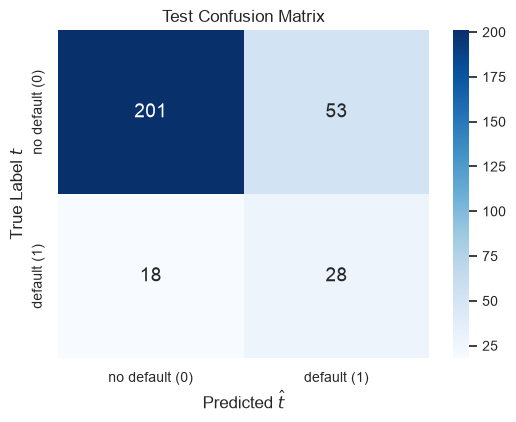

In [8]:
hp.plot_confusion_matrix(cm_test, labels=["no default (0)", "default (1)"],
                         title="Test Confusion Matrix", figsize=(5.5, 4.4))

Test AUC = 0.784; operating point at $\tau^\star = 0.20$: FPR = 0.209, TPR = 0.609

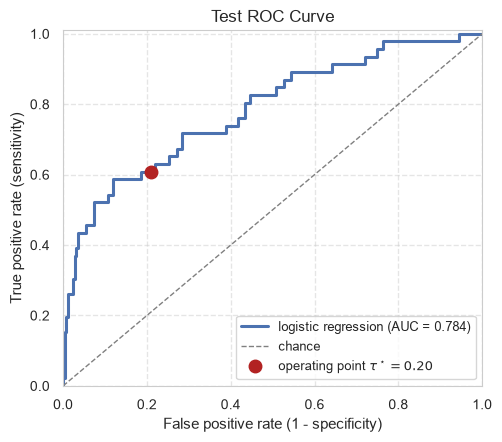

In [9]:
# ROC curve on the test set: TPR against FPR over all thresholds, its AUC, and the chosen
# operating point
fpr, tpr, roc_thresholds = roc_curve(t_test, y_test)
auc_test = roc_auc_score(t_test, y_test)
fpr_star, tpr_star = fp / (fp + tn), tp / (tp + fn)
display(Markdown(f"Test AUC = {auc_test:.3f}; operating point at $\\tau^\\star = {tau_star:.2f}$: "
                 f"FPR = {fpr_star:.3f}, TPR = {tpr_star:.3f}"))
hp.plot_roc_curves({f"logistic regression (AUC = {auc_test:.3f})": (fpr, tpr)},
                   points={rf"operating point $\tau^\star = {tau_star:.2f}$": (fpr_star, tpr_star)},
                   title="Test ROC Curve")

## Packaging the Model with `joblib`

- What is deployed is the **whole fitted pipeline**: the training means and standard deviations of the scaler and the weights of the logistic regression. The threshold $\tau^\star$ belongs to the decision and is deployed with it.
- Save scikit-learn pipelines with `joblib` (or `skops`, a format designed for safer loading); export PyTorch models with `torch.export` or to ONNX (`torch.onnx.export`).
- Record the scikit-learn version: a file saved with one version may fail to load, or behave differently, with another.

> ⚠️ **Important:** Loading a `.joblib` (pickle) file can execute arbitrary code. Only load files that you created yourself or that come from a trusted source.

In [10]:
# 5a. Packaging: save the fitted pipeline and load it back, as the serving process would
os.makedirs("models", exist_ok=True)
model_path = os.path.join("models", "loan_default_pipeline.joblib")
joblib.dump(model, model_path)

deployed_model = joblib.load(model_path)          # a trusted file: we created it ourselves
same_outputs = np.array_equal(deployed_model.predict_proba(X_test), model.predict_proba(X_test))
display(Markdown(f"Saved `{model_path}` with scikit-learn {sklearn.__version__}; "
                 f"the loaded pipeline reproduces the test probabilities: {same_outputs}"))

Saved `models/loan_default_pipeline.joblib` with scikit-learn 1.9.0; the loaded pipeline reproduces the test probabilities: True

In [11]:
# 5b. Model Serving: Mock REST API endpoint with a required-field check
def mock_predict_endpoint(request_json: dict, deployed_model, features: list,
                          threshold: float) -> dict:
    """Simulates a production REST microservice inference endpoint."""
    try:
        # Required-field check: every feature must be present in the request
        for feat in features:
            if feat not in request_json:
                return {"status": "error", "message": f"Missing required feature: {feat}"}

        # Format feature vector as DataFrame with feature names
        input_df = pd.DataFrame([[request_json[feat] for feat in features]], columns=features)
        # calibrated estimate of p(default | x)
        prob = float(deployed_model.predict_proba(input_df)[0, 1])
        prediction = int(prob >= threshold)

        return {
            "status": "success",
            "prediction": prediction,
            "decision": "REJECT_LOAN" if prediction == 1 else "APPROVE_LOAN",
            "default_probability": round(prob, 4),
            "threshold": round(threshold, 4),
            "model_version": "v1.2.0-prod"
        }
    except Exception as e:
        return {"status": "error", "message": str(e)}

In [12]:
# Test the serving function with a complete and with an incomplete payload
sample_payload = X_test.iloc[0].to_dict()
incomplete_payload = {feat: value for feat, value in sample_payload.items() if feat != "debt_ratio"}
print("=== Mock Production REST API Responses ===")
print(json.dumps(mock_predict_endpoint(sample_payload, deployed_model, feature_names, tau_star),
                 indent=2))
print(json.dumps(mock_predict_endpoint(incomplete_payload, deployed_model, feature_names,
                                       tau_star)))

=== Mock Production REST API Responses ===
{
  "status": "success",
  "prediction": 1,
  "decision": "REJECT_LOAN",
  "default_probability": 0.4588,
  "threshold": 0.2,
  "model_version": "v1.2.0-prod"
}
{"status": "error", "message": "Missing required feature: debt_ratio"}


## Simulating Covariate Shift

- **Scenario:** a marketing campaign attracts applicants with a low `risk_index`. The population of applicants, i.e. $p(\mathbf{x})$, changes.
- **Simulation:** draw 150 of the 300 test applicants without replacement, with selection probability proportional to $\exp(-r_n)$, where $r_n$ is the `risk_index` of applicant $n$, and keep their labels.
- Whether an applicant is selected depends on $\mathbf{x}$ only, so $p(t \mid \mathbf{x})$ is unchanged: **covariate shift, no concept drift**.
- **Monitoring without labels:** a two-sample **Kolmogorov–Smirnov (KS) test** per feature compares the production inputs with the training inputs. Its statistic is the largest distance between the two empirical cumulative distribution functions; a small $p$-value means that the two distributions differ.

In [13]:
# 6a. Monitoring: simulate covariate shift and test every input feature for drift
rng = np.random.default_rng(0)
# prefers applicants with a low risk_index
selection_weight = np.exp(-X_test["risk_index"].to_numpy())
production_idx = rng.choice(len(X_test), size=150, replace=False,
                            p=selection_weight / selection_weight.sum())
# labels kept: p(t | x) unchanged
X_prod, t_prod = X_test.iloc[production_idx], t_test.iloc[production_idx]

# significance level of each KS test
ALPHA = 0.01
drift_report = pd.DataFrame(
    [{"KS statistic": result.statistic, "p-value": result.pvalue}
     for result in (ks_2samp(X_train[feat], X_prod[feat]) for feat in feature_names)],
    index=feature_names,
)
drift_report["drift"] = drift_report["p-value"] < ALPHA
print(drift_report.to_string(formatters={"KS statistic": "{:.3f}".format,
                                         "p-value": "{:.1e}".format}))

drifted_features = drift_report.index[drift_report["drift"]].tolist()
if drifted_features:
    print(f"\nALERT: input drift in {drifted_features}: collect labels of recent applications, "
          "re-evaluate the model, then retrain or re-threshold (Continuous Training).")

                  KS statistic p-value  drift
credit_score             0.248 8.3e-08   True
debt_ratio               0.135 1.3e-02  False
income_stability         0.181 2.4e-04   True
inquiries_last_6m        0.099 1.3e-01  False
risk_index               0.300 3.0e-11   True
loan_amount              0.095 1.6e-01  False

ALERT: input drift in ['credit_score', 'income_stability', 'risk_index']: collect labels of recent applications, re-evaluate the model, then retrain or re-threshold (Continuous Training).


In [14]:
# 6b. Model quality before and after the shift (in production, the labels arrive later)
y_prod = model.predict_proba(X_prod)[:, 1]
t_pred_prod = (y_prod >= tau_star).astype(int)

monitoring = {}
for name, t_true, y_out, t_pred in [("test set", t_test, y_test, t_pred_test),
                                     ("shifted production sample", t_prod, y_prod, t_pred_prod)]:
    monitoring[name] = {
        "default rate": t_true.mean(),
        "mean predicted probability": y_out.mean(),
        "AUC": roc_auc_score(t_true, y_out),
        "precision": precision_score(t_true, t_pred, zero_division=0),
        "recall": recall_score(t_true, t_pred),
        "F1": f1_score(t_true, t_pred, zero_division=0),
        "average loss": decision_loss(t_true, t_pred, L_FN, L_FP).mean(),
    }
print(pd.DataFrame(monitoring).round(3))

                            test set  shifted production sample
default rate                   0.153                      0.107
mean predicted probability     0.164                      0.089
AUC                            0.784                      0.726
precision                      0.346                      0.333
recall                         0.609                      0.188
F1                             0.441                      0.240
average loss                   0.417                      0.387


## Retrain or Re-Threshold?

- **AUC and $F_1$ drop**, although neither the model nor $p(t \mid \mathbf{x})$ changed: the shifted population has fewer defaults and covers a narrower range of risk, so ranking is harder (AUC); the remaining defaults look like low-risk applicants, so fewer of them exceed the same threshold (recall, hence $F_1$).
- **The probabilities still fit:** the mean predicted probability still roughly matches the observed default rate, the estimate of $p(t \mid \mathbf{x})$ remains valid where the new applicants lie, and $\tau^\star$ is still the loss-minimizing threshold; the average loss did not rise.
- **Retrain** when labelled production data show that the probabilities are wrong: concept drift, or covariate shift into regions with little training data, where the model has to extrapolate.
- **Re-threshold** when the costs $\mathbf{L}$ change, or recalibrate when only the class frequencies change (prior probability shift).

> 💡 **Key Takeaway:** A drift alert starts an investigation (labels, calibration, expected loss); it is not automatically a reason to retrain.

# Summary & Key Takeaways

- **ML is Not Just Code**: MLOps manages the interconnected lifecycle of **Code + Data + Model**.
- **CRISP-ML(Q) Standard**: A 6-phase process model from business KPI formulation to post-deployment monitoring, with quality assurance (requirements, risks, checks) in every phase.
- **Data Splits**: Fit every preprocessing step on the training split only (a pipeline enforces it); use the validation set for choices and the test set once.
- **Inductive Bias & Baselines**: Every model makes assumptions; start simple and compare against a majority-class or heuristic baseline.
- **Decision Theory & Asymmetric Costs**: Choose decisions and thresholds by minimizing the expected loss ($\tau^\star = L_\mathrm{FP} / (L_\mathrm{FP} + L_\mathrm{FN})$ for calibrated probabilities); report precision, recall, $F_1$ and ROC/AUC next to the baseline, since accuracy misleads under class imbalance.
- **Serving Patterns**: Choose between REST microservices (real-time), Batch scoring (offline), and Embedded models (edge); package the whole fitted pipeline and load only trusted files.
- **Continuous Monitoring is Mandatory**: Models decay in non-stationary environments. Monitor the inputs (e.g. KS tests), because labels arrive late; a drift alert leads to re-evaluation, then retraining or re-thresholding (Continuous Training).

<small>📖 *Source: [ml-ops.org](https://ml-ops.org); Studer et al. (2021); Christopher M. Bishop and Hugh Bishop (2024)*</small>